In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


np.random.seed(42)


In [4]:

DATA_PATHS = [
    Path("/home/software-lab-706/perceptron_data/perceptron_data.csv"),
    Path("/home/software-lab-706/perceptron_data - perceptron_data.csv"),
    Path("perceptron_data.csv")
]


def load_perceptron_data(data_paths):
    """
    Load the binary classification dataset.

    The dataset should contain exactly two feature
    columns and one target / label column.
    """

    selected_path = None

    for path in data_paths:

        if path.exists() and path.is_file():
            selected_path = path
            break

    if selected_path is None:

        raise FileNotFoundError(
            "perceptron_data.csv was not found. "
            "Please check the instructor-provided file path."
        )

    data = pd.read_csv(selected_path)

    return data, selected_path


df, selected_path = load_perceptron_data(
    DATA_PATHS
)

print("Dataset path:", selected_path)
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())


Dataset path: perceptron_data.csv
Dataset shape: (100, 3)

First 5 rows:
         x1        x2  y
0  6.822060  7.896793  1
1  7.886186  6.174578  1
2  6.227460  7.307143  1
3  2.097078  2.968645 -1
4  1.470240  2.513267 -1


In [5]:

def prepare_data(data):

    columns = list(data.columns)

    target_candidates = [
        column
        for column in columns
        if str(column).strip().lower()
        in {"label", "target", "y", "class"}
    ]

    if len(target_candidates) > 0:
        target_column = target_candidates[0]
    else:

        target_column = columns[-1]

    feature_columns = [
        column
        for column in columns
        if column != target_column
    ]

    if len(feature_columns) != 2:

        raise ValueError(
            "The dataset must contain exactly two feature columns."
        )

    X = data[feature_columns].to_numpy(
        dtype=float
    )

    y_raw = data[target_column].to_numpy()
    unique_labels = pd.unique(y_raw)

    if len(unique_labels) != 2:

        raise ValueError(
            "The target must contain exactly two classes."
        )

    label_set = set(unique_labels.tolist())

    if label_set == {-1, 1}:

        y = y_raw.astype(float)

        label_mapping = {
            -1: -1,
            1: 1
        }

    elif label_set == {0, 1}:

        y = np.where(
            y_raw == 0,
            -1,
            1
        ).astype(float)

        label_mapping = {
            0: -1,
            1: 1
        }

    else:


        first_label = unique_labels[0]
        second_label = unique_labels[1]

        y = np.where(
            y_raw == first_label,
            -1,
            1
        ).astype(float)

        label_mapping = {
            first_label: -1,
            second_label: 1
        }

    return (
        X,
        y,
        feature_columns,
        target_column,
        label_mapping
    )


(
    X,
    y,
    feature_columns,
    target_column,
    label_mapping
) = prepare_data(df)

print("Feature columns:", feature_columns)
print("Target column:", target_column)
print("Label mapping:", label_mapping)

print("\nNumber of samples:", len(y))
print("Number of features:", X.shape[1])
print("Class -1 samples:", np.sum(y == -1))
print("Class +1 samples:", np.sum(y == 1))


Feature columns: ['x1', 'x2']
Target column: y
Label mapping: {-1: -1, 1: 1}

Number of samples: 100
Number of features: 2
Class -1 samples: 50
Class +1 samples: 50


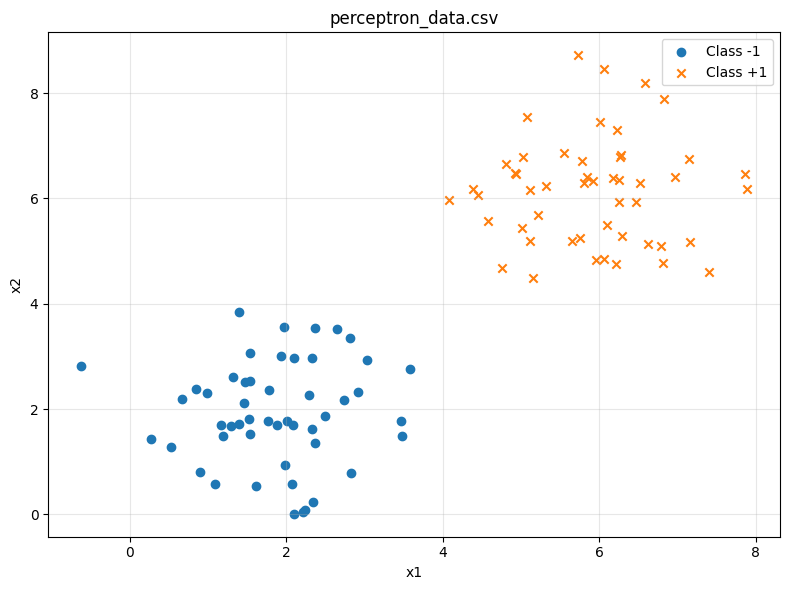

In [6]:
def plot_training_data(
    X,
    y,
    title="Perceptron Training Data"
):

    plt.figure(figsize=(8, 6))

    negative = (y == -1)
    positive = (y == 1)

    plt.scatter(
        X[negative, 0],
        X[negative, 1],
        marker="o",
        label="Class -1"
    )

    plt.scatter(
        X[positive, 0],
        X[positive, 1],
        marker="x",
        label="Class +1"
    )

    plt.xlabel(feature_columns[0])
    plt.ylabel(feature_columns[1])
    plt.title(title)

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_training_data(
    X,
    y,
    title="perceptron_data.csv"
)


##DECISION BOUNDARY FUNCTION

In [29]:

def plot_decision_boundary(
    X,
    y,
    weights,
    title="Decision Boundary"
):


    plt.figure(figsize=(8, 6))

    negative = (y == -1)
    positive = (y == 1)

    plt.scatter(
        X[negative, 0],
        X[negative, 1],
        marker="o",
        label="Class -1"
    )

    plt.scatter(
        X[positive, 0],
        X[positive, 1],
        marker="x",
        label="Class +1"
    )

    x1_min = X[:, 0].min() - 1
    x1_max = X[:, 0].max() + 1

    if abs(weights[2]) > 1e-12:

        x1_values = np.linspace(
            x1_min,
            x1_max,
            200
        )

        x2_values = (
            -(weights[0] + weights[1] * x1_values)
            / weights[2]
        )

        plt.plot(
            x1_values,
            x2_values,
            linewidth=2,
            label="Decision boundary"
        )

    elif abs(weights[1]) > 1e-12:

        x1_value = -weights[0] / weights[1]

        plt.axvline(
            x1_value,
            linewidth=2,
            label="Decision boundary"
        )

    else:

        print(
            "No valid line can be plotted because "
            "w1 and w2 are both zero."
        )

    plt.xlim(x1_min, x1_max)
    x2_min = X[:, 1].min() - 1
    x2_max = X[:, 1].max() + 1
    plt.ylim(x2_min, x2_max)
    plt.xlabel(feature_columns[0])
    plt.ylabel(feature_columns[1])
    plt.title(title)

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


## Desicion boundary random weights

Initial random weights:
w0 = 0.304717
w1 = -1.039984
w2 = 0.750451


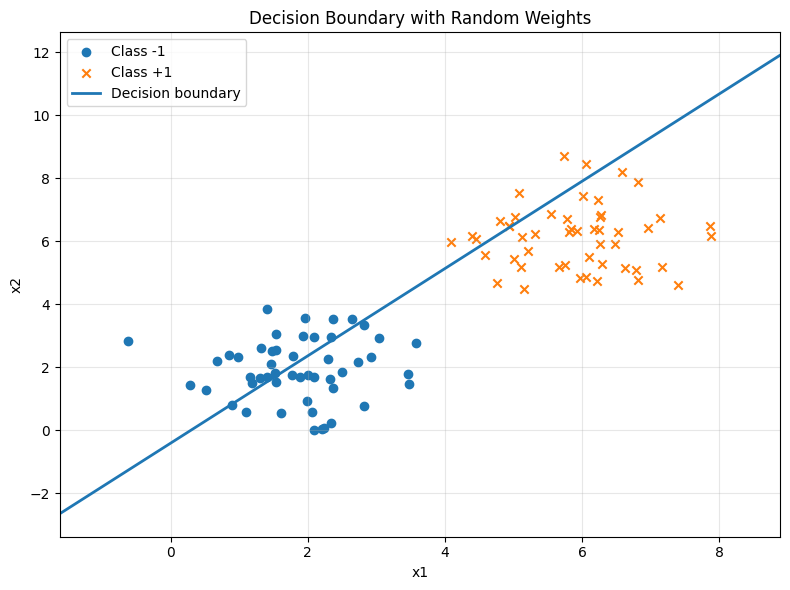

In [23]:
rng = np.random.default_rng(42)

random_weights = rng.normal(
    loc=0.0,
    scale=1.0,
    size=3
)

print("Initial random weights:")
print(f"w0 = {random_weights[0]:.6f}")
print(f"w1 = {random_weights[1]:.6f}")
print(f"w2 = {random_weights[2]:.6f}")

plot_decision_boundary(
    X,
    y,
    random_weights,
    title="Decision Boundary with Random Weights"
)


## Manual weights change

Manual weights:
w0 = -8.000000
w1 = 1.000000
w2 = 1.000000


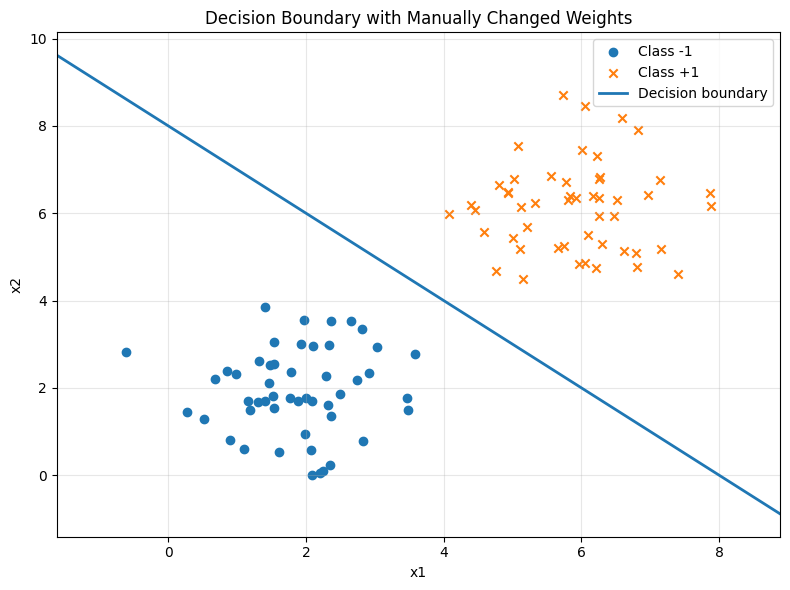

In [22]:

manual_weights = np.array([
    -8.0,
    1.0,
    1.0
])

print("Manual weights:")
print(f"w0 = {manual_weights[0]:.6f}")
print(f"w1 = {manual_weights[1]:.6f}")
print(f"w2 = {manual_weights[2]:.6f}")

plot_decision_boundary(
    X,
    y,
    manual_weights,
    title="Decision Boundary with Manually Changed Weights"
)


## PERCEPTRON FUNCTIONS

In [10]:
def initialize_parameters(
    n_features,
    seed=42
):

    rng = np.random.default_rng(seed)

    weights = rng.normal(
        loc=0.0,
        scale=0.5,
        size=n_features + 1
    )

    return weights


## Predict

In [11]:

def predict(
    X,
    weights
):
       # +1, if score >= 0
        #-1, otherwise

    X = np.asarray(
        X,
        dtype=float
    )

    if X.ndim == 1:
        X = X.reshape(1, -1)

    X_with_bias = np.column_stack((
        np.ones(len(X)),
        X
    ))

    scores = X_with_bias.dot(
        weights
    )

    predictions = np.where(
        scores >= 0,
        1,
        -1
    )

    return predictions


## Perceptio loss / classification error

In [12]:
def compute_loss(
    X,
    y,
    weights
):

    predictions = predict(
        X,
        weights
    )

    loss = np.sum(
        predictions != y
    )

    return int(loss)


## Weight update

In [13]:
def update_weights(
    x,
    y,
    weights,
    learning_rate=1.0
):


    x = np.asarray(
        x,
        dtype=float
    )

    x_with_bias = np.insert(
        x,
        0,
        1.0
    )

    score = weights.dot(
        x_with_bias
    )

    if y * score <= 0:

        weights = (
            weights
            + learning_rate
            * y
            * x_with_bias
        )

        return weights, True

    return weights, False


## Train perceptron

In [14]:


def train_perceptron(
    X,
    y,
    learning_rate=1.0,
    epochs=100,
    initial_weights=None,
    seed=42
):

      #  1. Calculate the prediction.
      #  2. Compare it with the actual label.
      #  3. If misclassified, update the weights.

    X = np.asarray(
        X,
        dtype=float
    )

    y = np.asarray(
        y,
        dtype=float
    )

    if initial_weights is None:

        weights = initialize_parameters(
            X.shape[1],
            seed=seed
        )

    else:

        weights = np.asarray(
            initial_weights,
            dtype=float
        ).copy()

    error_history = []

    for epoch in range(epochs):

        for i in range(len(y)):

            prediction = predict(
                X[i],
                weights
            )[0]

            if prediction != y[i]:

                weights, updated = update_weights(
                    X[i],
                    y[i],
                    weights,
                    learning_rate=learning_rate
                )

        errors = compute_loss(
            X,
            y,
            weights
        )

        error_history.append(
            errors
        )

        if errors == 0:
            break

    return (
        weights,
        error_history
    )


Initial perceptron weights:
w0 = 0.152359
w1 = -0.519992
w2 = 0.375226


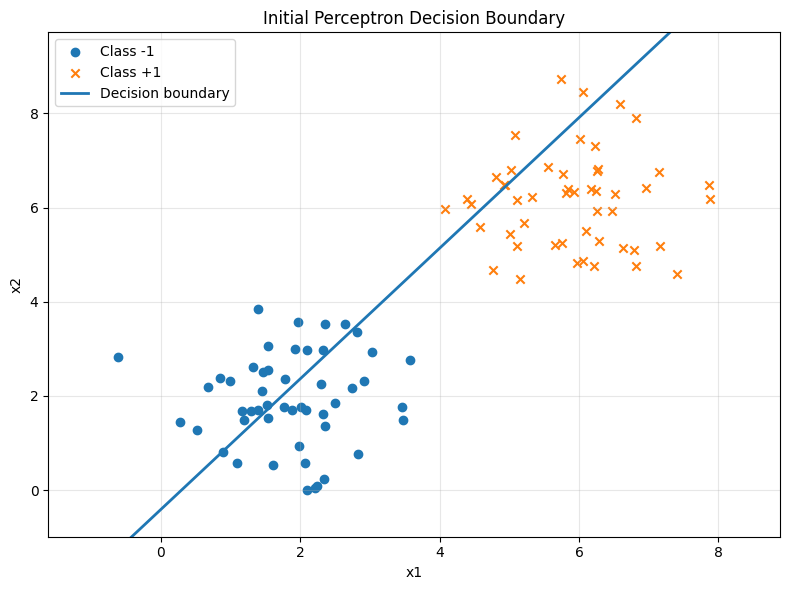

Final perceptron weights:
w0 = -13.847641
w1 = 3.117442
w2 = 0.383052


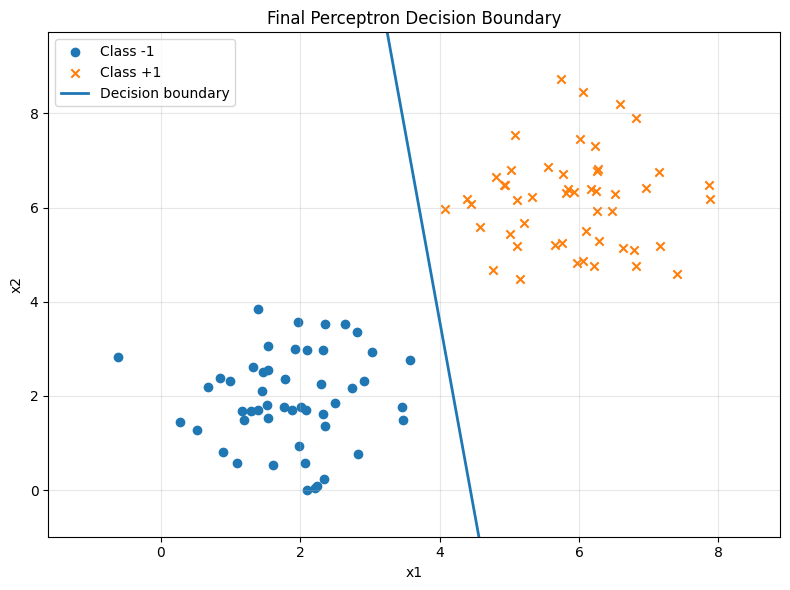

In [28]:
initial_weights = initialize_parameters(
    X.shape[1],
    seed=42
)

print("Initial perceptron weights:")
print(f"w0 = {initial_weights[0]:.6f}")
print(f"w1 = {initial_weights[1]:.6f}")
print(f"w2 = {initial_weights[2]:.6f}")

plot_decision_boundary(
    X,
    y,
    initial_weights,
    title="Initial Perceptron Decision Boundary"
)

(
    final_weights,
    error_history
) = train_perceptron(
    X,
    y,
    learning_rate=1.0,
    epochs=100,
    initial_weights=initial_weights,
    seed=42
)

print("Final perceptron weights:")
print(f"w0 = {final_weights[0]:.6f}")
print(f"w1 = {final_weights[1]:.6f}")
print(f"w2 = {final_weights[2]:.6f}")

plot_decision_boundary(
    X,
    y,
    final_weights,
    title="Final Perceptron Decision Boundary"
)


In [30]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML


def train_with_history(X, y, initial_weights, learning_rate=1.0, epochs=100):
    """Same as train_perceptron, but saves the weights after every update."""
    weights = np.asarray(initial_weights, dtype=float).copy()
    history = [(weights.copy(), "Initial weights")]

    for epoch in range(1, epochs + 1):
        for i in range(len(y)):
            if predict(X[i], weights)[0] != y[i]:
                weights, _ = update_weights(
                    X[i], y[i], weights, learning_rate=learning_rate
                )
                history.append(
                    (weights.copy(), f"Epoch {epoch}, update on sample {i}")
                )

        if compute_loss(X, y, weights) == 0:
            break

    return history


def animate_boundary(X, y, history, interval=800):
    fig, ax = plt.subplots(figsize=(8, 6))

    neg = (y == -1)
    pos = (y == 1)
    ax.scatter(X[neg, 0], X[neg, 1], marker="o", label="Class -1")
    ax.scatter(X[pos, 0], X[pos, 1], marker="x", label="Class +1")

    x1_vals = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200)

    ax.set_xlim(x1_vals[0], x1_vals[-1])
    ax.set_ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
    ax.set_xlabel(feature_columns[0] if len(feature_columns) == 2 else "x1")
    ax.set_ylabel("x2")
    ax.grid(alpha=0.3)

    (line,) = ax.plot([], [], color="red", linewidth=2, label="Decision boundary")
    title = ax.set_title("")
    ax.legend(loc="upper right")

    def update(frame):
        w, text = history[frame]

        if abs(w[2]) > 1e-12:
            line.set_data(x1_vals, -(w[0] + w[1] * x1_vals) / w[2])
        elif abs(w[1]) > 1e-12:
            line.set_data([-w[0] / w[1]] * 2, ax.get_ylim())

        errors = compute_loss(X, y, w)
        title.set_text(f"{text} | errors = {errors}")
        return line, title

    anim = FuncAnimation(
        fig, update, frames=len(history), interval=interval, repeat=True
    )
    plt.close(fig)
    return anim



history = train_with_history(X, y, initial_weights)
print("Total frames (updates + initial):", len(history))

anim = animate_boundary(X, y, history)
HTML(anim.to_jshtml())

Total frames (updates + initial): 31


In [34]:
show_boundary("Initial boundary", initial_weights)
show_boundary("Final boundary", final_weights)

Initial boundary
  weights   : w0=0.1524, w1=-0.5200, w2=0.3752
  slope     : m = -w1/w2 = 1.3858
  intercept : c = -w0/w2 = -0.4060
  equation  : x2 = 1.3858*x1 + -0.4060

Final boundary
  weights   : w0=-13.8476, w1=3.1174, w2=0.3831
  slope     : m = -w1/w2 = -8.1384
  intercept : c = -w0/w2 = 36.1508
  equation  : x2 = -8.1384*x1 + 36.1508



## classification errors against epochs

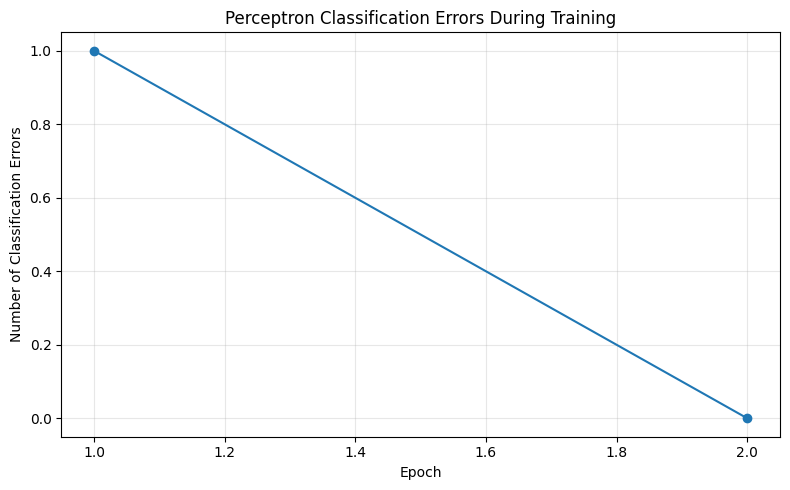

Error history:
[1, 0]


In [16]:
epochs_used = np.arange(
    1,
    len(error_history) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_used,
    error_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Number of Classification Errors")
plt.title("Perceptron Classification Errors During Training")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Error history:")
print(error_history)


In [26]:
print(
    f"\nFinal training accuracy = "
    f"{final_accuracy * 100:.2f}%"
)



Final training accuracy = 100.00%


## XOR Dataset

XOR dataset:
 x1  x2  Label
  0   0      1
  0   1     -1
  1   0     -1
  1   1      1


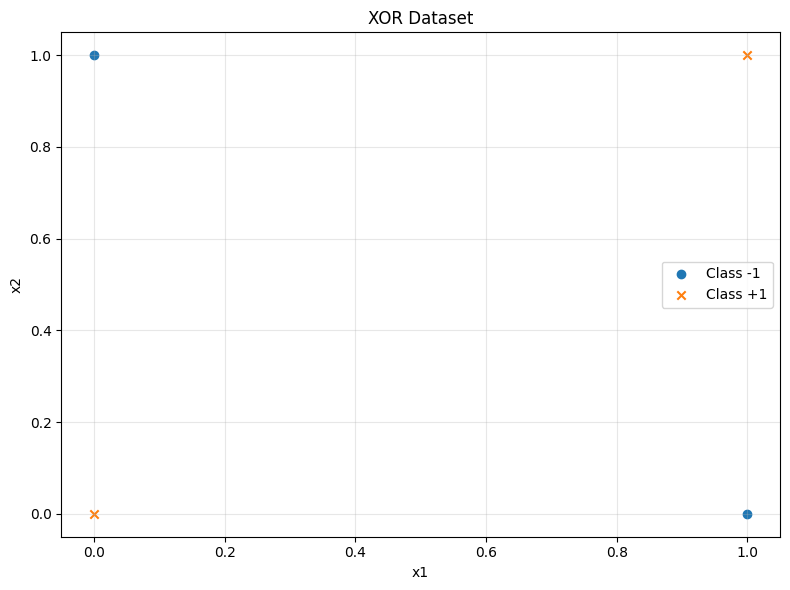

In [18]:
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y_xor = np.array([
    1,
    -1,
    -1,
    1
], dtype=float)

print("XOR dataset:")

xor_table = pd.DataFrame({
    "x1": X_xor[:, 0].astype(int),
    "x2": X_xor[:, 1].astype(int),
    "Label": y_xor.astype(int)
})

print(xor_table.to_string(index=False))

plot_training_data(
    X_xor,
    y_xor,
    title="XOR Dataset"
)


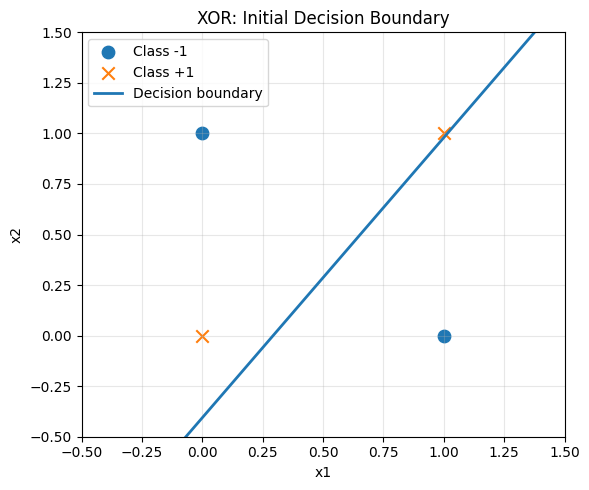

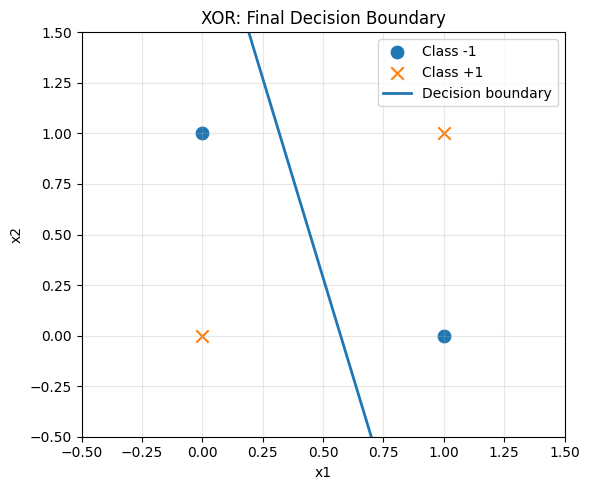

In [24]:
def plot_xor_boundary(X, y, weights, title):
    plt.figure(figsize=(6, 5))

    neg = (y == -1)
    pos = (y == 1)
    plt.scatter(X[neg, 0], X[neg, 1], marker="o", s=80, label="Class -1")
    plt.scatter(X[pos, 0], X[pos, 1], marker="x", s=80, label="Class +1")

    x1_vals = np.linspace(-0.5, 1.5, 200)

    if abs(weights[2]) > 1e-12:
        x2_vals = -(weights[0] + weights[1] * x1_vals) / weights[2]
        plt.plot(x1_vals, x2_vals, linewidth=2, label="Decision boundary")
    elif abs(weights[1]) > 1e-12:
        plt.axvline(-weights[0] / weights[1], linewidth=2, label="Decision boundary")

    plt.xlim(-0.5, 1.5)
    plt.ylim(-0.5, 1.5)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_xor_boundary(X_xor, y_xor, xor_initial_weights,
                  "XOR: Initial Decision Boundary")

plot_xor_boundary(X_xor, y_xor, xor_final_weights,
                  "XOR: Final Decision Boundary")

## Apply perceptron

In [19]:
xor_initial_weights = initialize_parameters(
    X_xor.shape[1],
    seed=42
)

(
    xor_final_weights,
    xor_error_history
) = train_perceptron(
    X_xor,
    y_xor,
    learning_rate=1.0,
    epochs=20,
    initial_weights=xor_initial_weights,
    seed=42
)

xor_predictions = predict(
    X_xor,
    xor_final_weights
)

xor_errors = compute_loss(
    X_xor,
    y_xor,
    xor_final_weights
)

xor_accuracy = np.mean(
    xor_predictions == y_xor
)

print("Initial XOR weights:")
print(xor_initial_weights)

print("\nFinal XOR weights:")
print(xor_final_weights)

print("\nXOR error history:")
print(xor_error_history)

print("\nFinal XOR predictions:")
print(xor_predictions.astype(int))

print(
    f"\nFinal XOR classification errors = {xor_errors}"
)

print(
    f"Final XOR training accuracy = "
    f"{xor_accuracy * 100:.2f}%"
)


Initial XOR weights:
[ 0.15235854 -0.51999205  0.3752256 ]

Final XOR weights:
[-0.84764146  1.48000795  0.3752256 ]

XOR error history:
[2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]

Final XOR predictions:
[-1 -1  1  1]

Final XOR classification errors = 2
Final XOR training accuracy = 50.00%


In [31]:
xor_history = train_with_history(X_xor, y_xor, xor_initial_weights, epochs=20)
xor_anim = animate_boundary(X_xor, y_xor, xor_history)
HTML(xor_anim.to_jshtml())

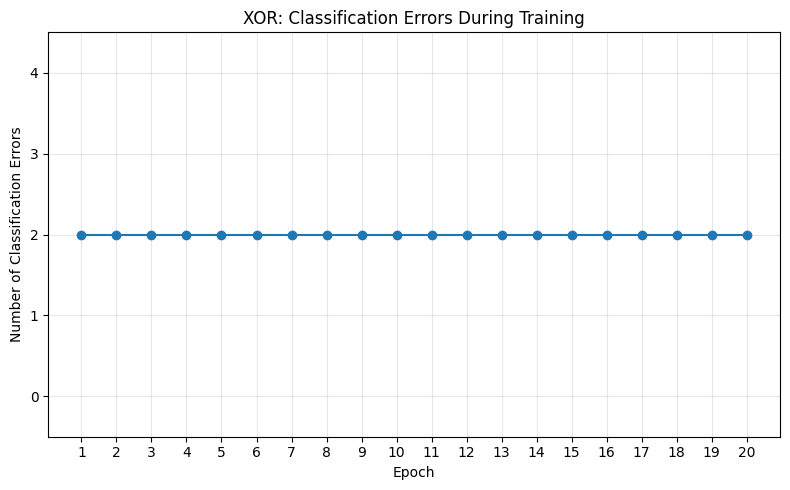

In [25]:
xor_epochs = np.arange(1, len(xor_error_history) + 1)

plt.figure(figsize=(8, 5))
plt.plot(xor_epochs, xor_error_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Number of Classification Errors")
plt.title("XOR: Classification Errors During Training")
plt.ylim(-0.5, 4.5)
plt.xticks(xor_epochs)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
def boundary_slope_intercept(weights):
    w0, w1, w2 = weights

    if abs(w2) < 1e-12:
        return None, None

    slope = -w1 / w2
    intercept = -w0 / w2
    return slope, intercept


def show_boundary(name, weights):
    m, c = boundary_slope_intercept(weights)

    print(name)
    print(f"  weights   : w0={weights[0]:.4f}, w1={weights[1]:.4f}, w2={weights[2]:.4f}")

    if m is None:
        print(f"  slope     : undefined (vertical line, x1 = {-weights[0]/weights[1]:.4f})")
    else:
        print(f"  slope     : m = -w1/w2 = {m:.4f}")
        print(f"  intercept : c = -w0/w2 = {c:.4f}")
        print(f"  equation  : x2 = {m:.4f}*x1 + {c:.4f}")
    print()

show_boundary("Initial boundary", initial_weights)
show_boundary("Final boundary", final_weights)

show_boundary("XOR initial boundary", xor_initial_weights)
show_boundary("XOR final boundary", xor_final_weights)

Initial boundary
  weights   : w0=0.1524, w1=-0.5200, w2=0.3752
  slope     : m = -w1/w2 = 1.3858
  intercept : c = -w0/w2 = -0.4060
  equation  : x2 = 1.3858*x1 + -0.4060

Final boundary
  weights   : w0=-13.8476, w1=3.1174, w2=0.3831
  slope     : m = -w1/w2 = -8.1384
  intercept : c = -w0/w2 = 36.1508
  equation  : x2 = -8.1384*x1 + 36.1508

XOR initial boundary
  weights   : w0=0.1524, w1=-0.5200, w2=0.3752
  slope     : m = -w1/w2 = 1.3858
  intercept : c = -w0/w2 = -0.4060
  equation  : x2 = 1.3858*x1 + -0.4060

XOR final boundary
  weights   : w0=-0.8476, w1=1.4800, w2=0.3752
  slope     : m = -w1/w2 = -3.9443
  intercept : c = -w0/w2 = 2.2590
  equation  : x2 = -3.9443*x1 + 2.2590

